<a href="https://colab.research.google.com/github/Jayadeep19/pytorch/blob/master/pytorch/MLP/Multi_layer_perceptron_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MLP-regression problem
- In this notebook, we will build a Multi layer perceptorn to predict the sine of an input number over a region, using the pytorch functions, I documented in the last [notebook](https://github.com/Jayadeep19/pytorch/blob/master/pytorch/basics/Models_and_optimizers.ipynb).
- By predicting the sine of a number, I mean is we train a MLP(see my blog on [MLP](https://jayadeep19.github.io/til-notes/back-propagation#multi-layer-perceptron)) to predict the mean of a distribution over a possible output values. The mean of this distribution is supposed to be the the true target values that we desire (In a perfect world!)
-


In [150]:
import numpy
from matplotlib import pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
# we also use the other modules like DataLoader and Dataset frm pytorch.
from torch.utils.data import DataLoader
from torch.utils.data.dataset import Dataset

from tqdm.notebook import tqdm

## pytorch Datasets and DataLoader

- I will make a seperate notebook on Datasets and DataLoaders from pytorch in another notebook.
- untill now we handled mnist dataset using manual slicing like `xb = train_dataset[start_i : end_i]`. But pytorch provides a standardized toolkit for managing data.
### Datasets
- pytorch provides datasets for us to work with in our problems (tasks).
- We can load them directly from the pytorch using the `import torch.utils.data.dataset import Dataset`. we can load them as
  1. load the dataset all at once in the initilisation function
  2. Load them as chunks or only the chunks of paths if the dataset is too large (like datasets of images)

### DataLoader
- These loaded datasets then can be used to create a `DataLoader` object, it is an iterable that can be iterated on either the whole dataset or the chunks that are loaded.
- The dataloader is very useful in generating mini batches of the data for our Gradient descent steps. They also can be shufle it before passing it to the model for each epoch.

### torch.utils.data.dataset
- To create our dataset, we have to look at the two main methods `__len__` and `__getitem__`.
- `__len__`, this function is called during every iteration
- `__getitem__`, this function returns the length of the dataset
- Let us prepare our sin wave dataset in the range of -9 to 9 on the x axis.
- We will also introduce some noise into the labels of those x-values.

In [151]:
# create a class, SinDataset and import the parent class(Dataset class) characteristics

class SinDataset(Dataset):
  '''
  Creates a dataset of 'num_datapoints' length with noisy target values.
  Then our target for the regression becomes, to find the function that approximates and fits our noisy target values. (predict them)
  '''
  def __init__(self, num_datapoints):
    '''we will create the x- values in the range [-9,9], we can make sure that we produce
    a random uniformly distributed points with torch.randn'''
    # randn produces numbers from 0-1.0 and we then scale them to max 18:[0-18] and
    # subtract '9' from each to make them fall the desired range.
    self.x_data = torch.rand(num_datapoints,1) *18 -9

    # we can scale the target values 2.5 time to make the training faster and stable.
    self.y_data = (torch.sin(self.x_data))/2.5

    # we can add uniform noise to our scaled target values by
    self.y_data += torch.rand_like(self.y_data)/20

  def __getitem__(self, index):
    '''
    This function is called by the DataLoader class whenever we it wants a new mini batch
    Note: Pytorch passes the `__getitem__` function only one index at a time, if we use multiple `__getitem__` methods with multiple DataLoader workers, then pytorch calls the __getitem functions
    PARALLALY. It creates multiple threads.
    '''
    return self.x_data[index], self.y_data[index]

  def __len__(self):
    return self.x_data.shape[0]

- Now we can create instances of `DataLoader` to load data and make mini batchs to pass to the model.

In [152]:
train_nx = 30000    #no of points in train dataset
test_nx = 8000      # no of points in test dataset
batch_size = 256

# we can create the train and test data

train_data = SinDataset(train_nx)
test_data = SinDataset(test_nx)

#Create a DataLoader object for train and test data
train_dataloader  = DataLoader(dataset= train_data, batch_size = batch_size, shuffle = True)
test_dataloader  = DataLoader(dataset= test_data, batch_size = batch_size, shuffle = True)

In [153]:
train_dataloader

- we can visualise the dataset.

Text(0.5, 1.0, 'the data we try to approximate our function to')

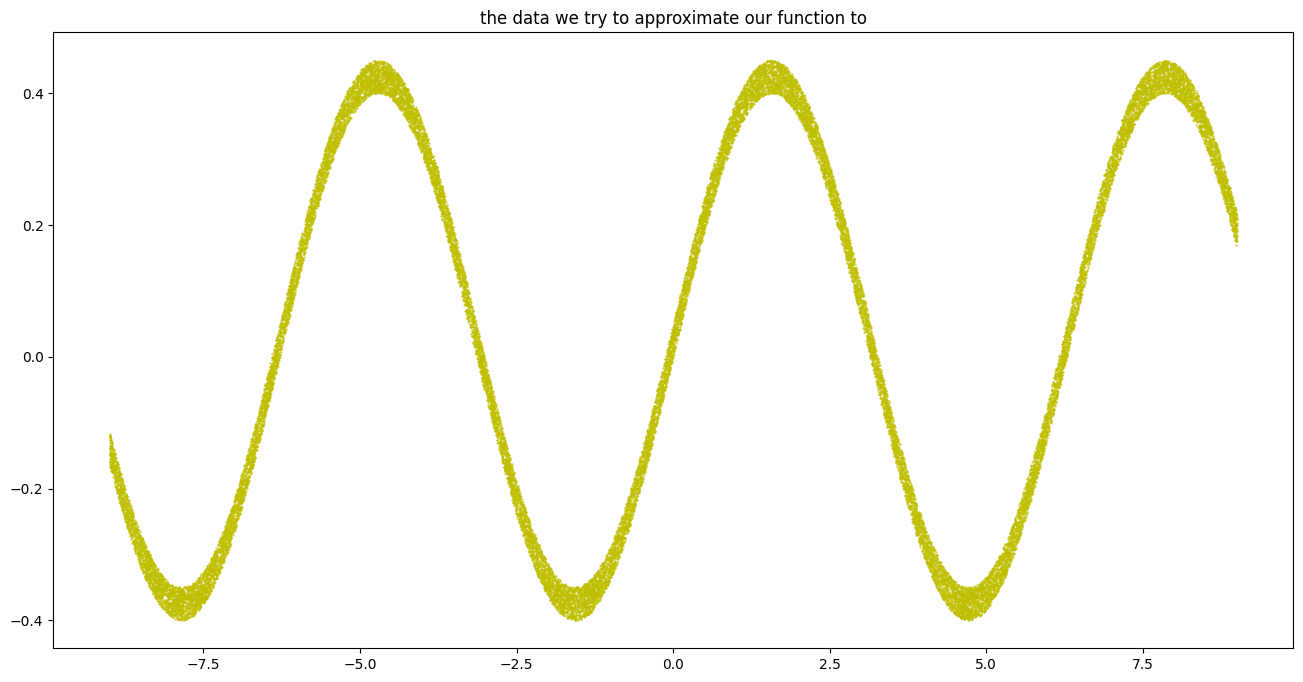

In [154]:
fig = plt.figure(figsize=(16, 8))
plt.scatter(train_data.x_data, train_data.y_data, s = 0.2, color = 'y')
plt.title('the data we try to approximate our function to')

##

## Our Network architecture
- As we can see our data is not linear, se we will benifit from using a non linear model to approximate our function.
- We can achieve this by using linear layers with non linear activation functions such as 'relu, tanh or sigmoid'
- These non linear activation functions introduce non linearity to our model, making it be able to learn complex patterns.
  - these implementations can be imported from pytorch mainly in three different weays
  1. `torch.<activation function>`
  2. `nn.<activation function>`
  3. `nn.Functional.<activation function>`

- also we can find loss functions in  as we are in regression, we can use MSELoss()
  1. `torch.<loss function>`
  2. `nn.Fuctional.<loss function>`

- we will use **'tanh'** in our model and we will build 4 layers
  - 1 Input layer
  - 2 hidden layers
  - 1 output layer

In [155]:
# create our regression model.
class sinPredictor(nn.Module):

  def __init__(self, input_size, hidden_size, output_size):
    super(sinPredictor, self).__init__()

    self.input_layer = nn.Linear(input_size, hidden_size)
    self.layer2 = nn.Linear(hidden_size, hidden_size)
    self.layer3 = nn.Linear(hidden_size, hidden_size)
    self.output_layer = nn.Linear(hidden_size, output_size)

  def forward(self,x):

    #layer 1
    x = self.input_layer(x)
    x = torch.tanh(x)

    #layer 2
    x = self.layer2(x)
    x = torch.tanh(x)

    #layer 3
    x = self.layer3(x)
    x = torch.tanh(x)

    #layer 5 - no activation function as we need raw logits to pass to the optimizer(expects raw logits).
    x = self.output_layer(x)

    return x

In [156]:
# we can now define the hyper parametes , loss function and optimizer

lr = 5e-4
epochs = 10

# create a model object
sin_predictor = sinPredictor(input_size=1, hidden_size=64, output_size= 1)

# loss function- can be found in nn module or functional
loss_fn = nn.MSELoss()

# optimizer
optmizer = optim.Adam(sin_predictor.parameters(), lr = lr)

- Now we can write our training loop.
- we have `epoch` number of epochs for the whole dataset.
- we have also defined our DataLoaders. these produce mini batches of the dataset, which we will pass one instance at a time to the model `input_sie = 1`.
  - meaning, for each epoch, we will have to iterate '30000/256' batches.

- we can use tqdm to track our progress interactively

In [157]:
#initiate loggers
train_loss_logger = []
test_loss_logger = []


# start our epochs
for epoch in tqdm(range(epochs), desc = 'Epochs --> '):
  # start the iterations
  for x, y in tqdm(train_dataloader, desc = '   Training iterations:'):

    y_predict = sin_predictor(x)

    loss = loss_fn(y_predict, y)

    train_loss_logger.append(loss.item())

    loss.backward()

    optmizer.step()

    optmizer.zero_grad()

  # perform test for each epoch
  with torch.no_grad():
    init_loss = 0   #loss accumulation

    for i, (x,y) in enumerate(tqdm(test_dataloader, desc = 'Testing', leave = False)):

      test_y_pred = sin_predictor(x)

      t_loss = loss_fn(test_y_pred, y)

      test_loss_logger.append(t_loss.item())

      init_loss += t_loss.item()

    init_loss /= (i+1)

print("Epoch [%d/%d], Average Test Loss %.4f" %(epoch+1, epochs, init_loss))



Epochs --> :   0%|          | 0/10 [00:00<?, ?it/s]

   Training iterations::   0%|          | 0/118 [00:00<?, ?it/s]

Testing:   0%|          | 0/32 [00:00<?, ?it/s]

   Training iterations::   0%|          | 0/118 [00:00<?, ?it/s]

Testing:   0%|          | 0/32 [00:00<?, ?it/s]

...

   Training iterations::   0%|          | 0/118 [00:00<?, ?it/s]

Testing:   0%|          | 0/32 [00:00<?, ?it/s]

   Training iterations::   0%|          | 0/118 [00:00<?, ?it/s]

Testing:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch [10/10], Average Test Loss 0.0102


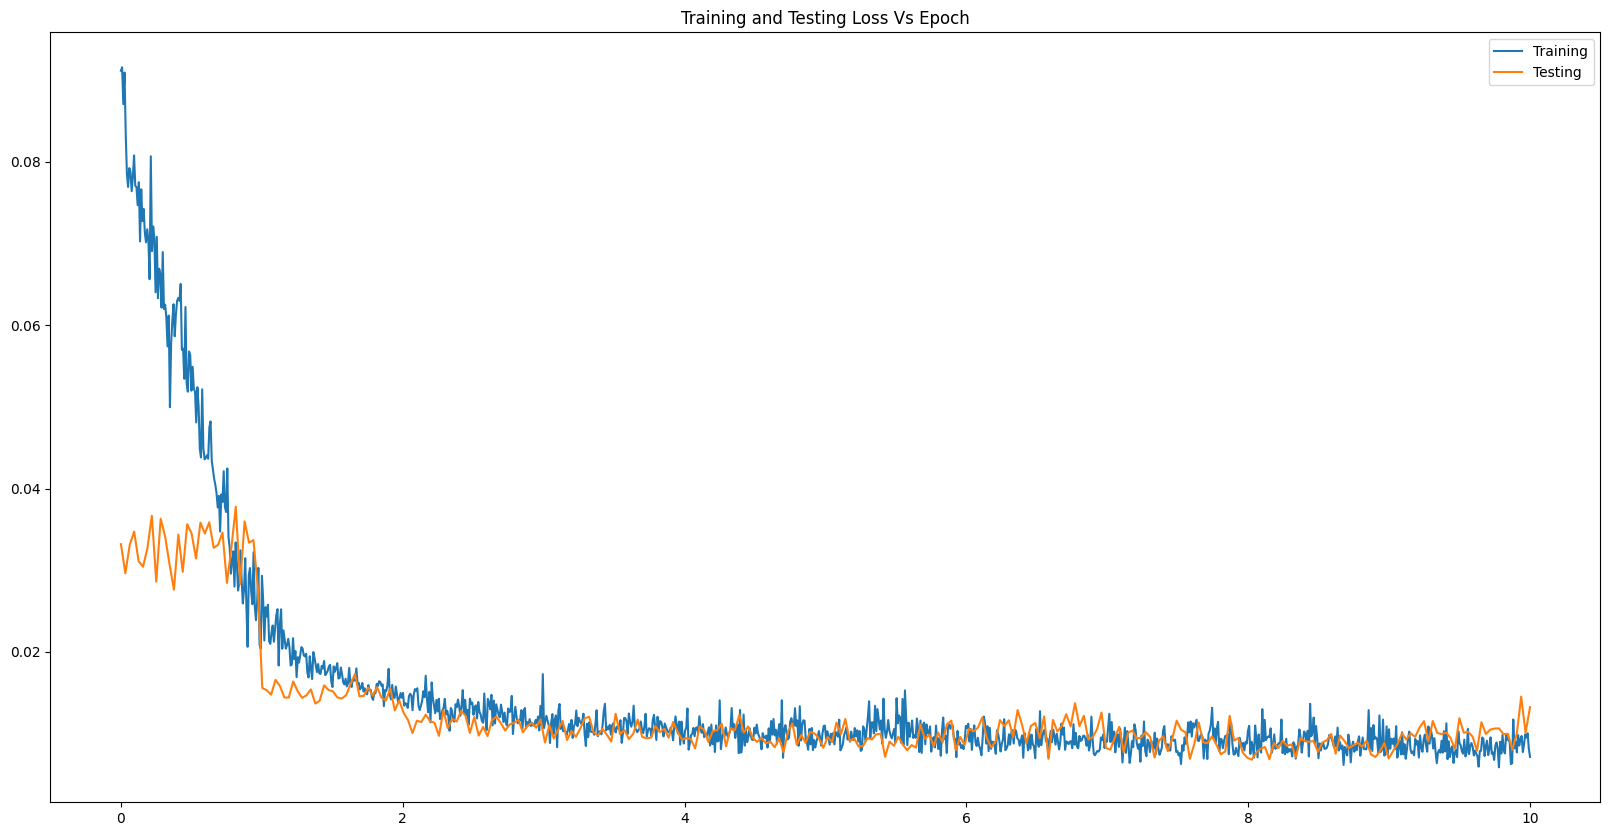

In [158]:
fig = plt.figure(figsize=(20, 10))
plt.plot(numpy.linspace(0, epochs, len(train_loss_logger)), train_loss_logger)
plt.plot(numpy.linspace(0, epochs, len(test_loss_logger)), test_loss_logger)
title = plt.title("Training and Testing Loss Vs Epoch")
legend = plt.legend(["Training", "Testing"])

- plot the test set predictions against the actual test set labels

In [159]:
predictions = []

with torch.no_grad():
  for x in test_data.x_data:
    y_predicted = sin_predictor(x)
    predictions.append(y_predicted.detach().cpu().squeeze(-1))

#predictions = torch.cat(predictions).numpy()

In [160]:
print(len(predictions))

8000


Text(-9, 0.48, '- Sine wave (with noise)')

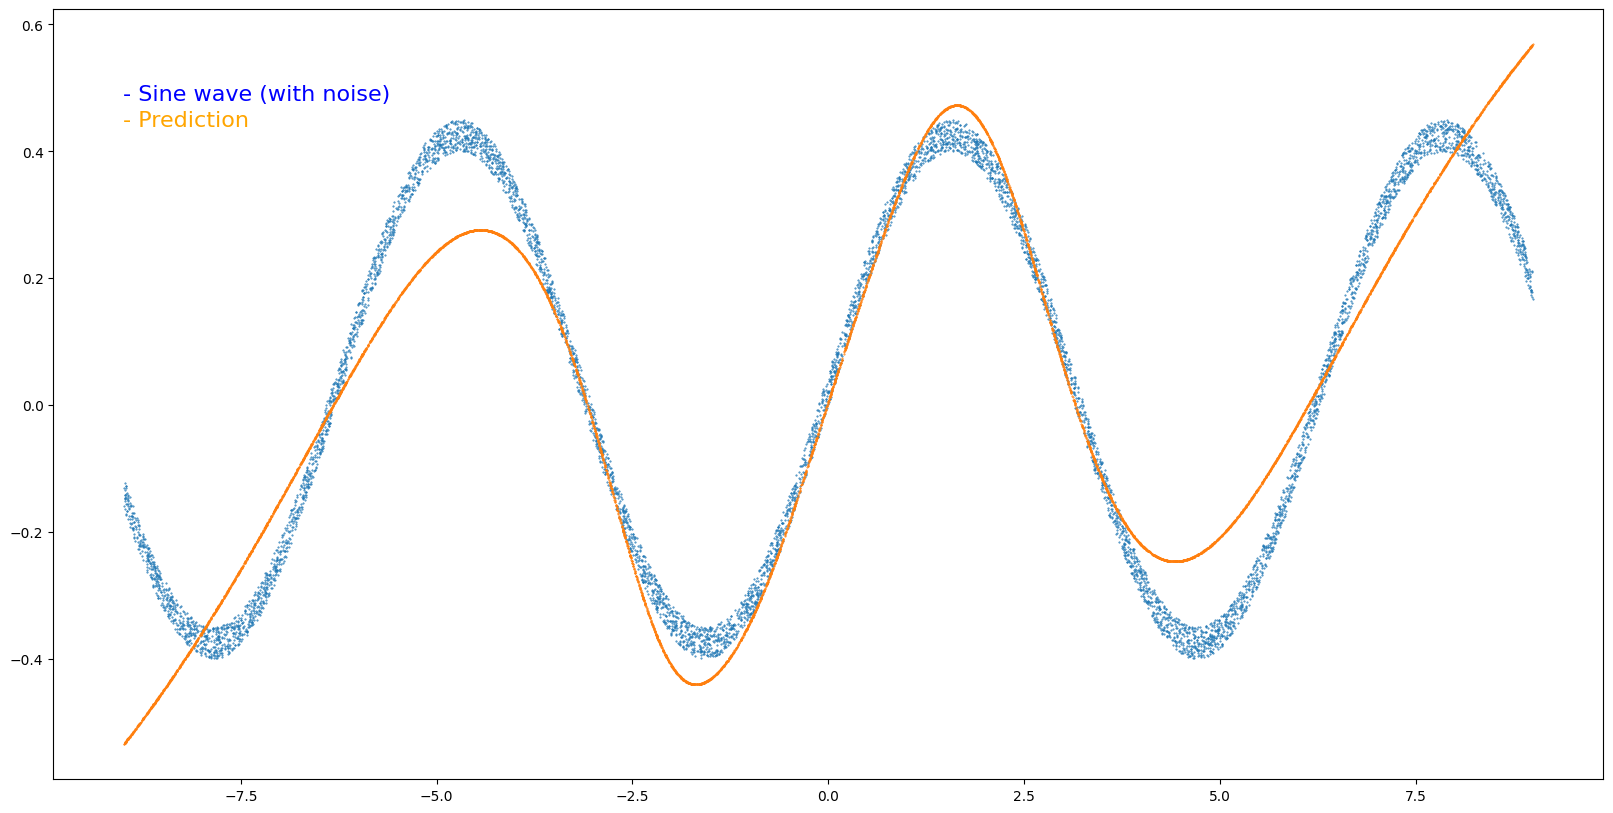

In [161]:
# Plot the testdata against the model's predicted outputs, how accurate is it?
fig = plt.figure(figsize=(20, 10))
plt.scatter(test_data.x_data, test_data.y_data, s=0.2)
plt.scatter(test_data.x_data, predictions, s = 0.2)
plt.text(-9, 0.44, "- Prediction", color="orange", fontsize=16)
plt.text(-9, 0.48, "- Sine wave (with noise)", color="blue", fontsize=16)

- Since our predictions are not very accurate, we can now:
1. Increase the complexity of our model (more layers)
2. decrease the learning rate more
3. Since the training error is still going down, we can train more epochs.